I will be using the Global Power Plant Database 
https://datasets.wri.org/datasets/global-power-plant-database

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data loading and EDA

In [14]:
data_path = 'data/raw/global_power_plant_database.csv'
df = pd.read_csv(data_path)
df.head()

C:\Users\asier\AppData\Local\Temp\ipykernel_23144\968640171.py:2: DtypeWarning: Columns (0: other_fuel3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
0,AFG,Afghanistan,Kajaki Hydroelectric Power Plant Afghanistan,GEODB0040538,33.0,32.322,65.1190,Hydro,NaN,NaN,...,123.77,162.90,97.39,137.76,119.50,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
1,AFG,Afghanistan,Kandahar DOG,WKS0070144,10.0,31.670,65.7950,Solar,NaN,NaN,...,18.43,17.48,18.25,17.70,18.29,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
2,AFG,Afghanistan,Kandahar JOL,WKS0071196,10.0,31.623,65.7920,Solar,NaN,NaN,...,18.64,17.58,19.10,17.62,18.72,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
3,AFG,Afghanistan,Mahipar Hydroelectric Power Plant Afghanistan,GEODB0040541,66.0,34.556,69.4787,Hydro,NaN,NaN,...,225.06,203.55,146.90,230.18,174.91,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
4,AFG,Afghanistan,Naghlu Dam Hydroelectric Power Plant Afghanistan,GEODB0040534,100.0,34.641,69.7170,Hydro,NaN,NaN,...,406.16,357.22,270.99,395.38,350.80,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1


In [15]:
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print(df.dtypes)

missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_summary = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percentage})

print("\n--- Columns with Missing Values ---")
print(missing_summary[missing_summary['Missing Values'] > 0].sort_values(by='Percentage (%)', ascending=False))

Dataset Shape: 34936 rows, 36 columns

country                               str
country_long                          str
name                                  str
gppd_idnr                             str
capacity_mw                       float64
latitude                          float64
longitude                         float64
primary_fuel                          str
other_fuel1                           str
other_fuel2                           str
other_fuel3                           str
commissioning_year                float64
owner                                 str
source                                str
url                                   str
geolocation_source                    str
wepp_id                               str
year_of_capacity_data             float64
generation_gwh_2013               float64
generation_gwh_2014               float64
generation_gwh_2015               float64
generation_gwh_2016               float64
generation_gwh_2017               flo

count    34936.000000
mean       163.355148
std        489.636072
min          1.000000
25%          4.900000
50%         16.745000
75%         75.344250
max      22500.000000
Name: capacity_mw, dtype: float64


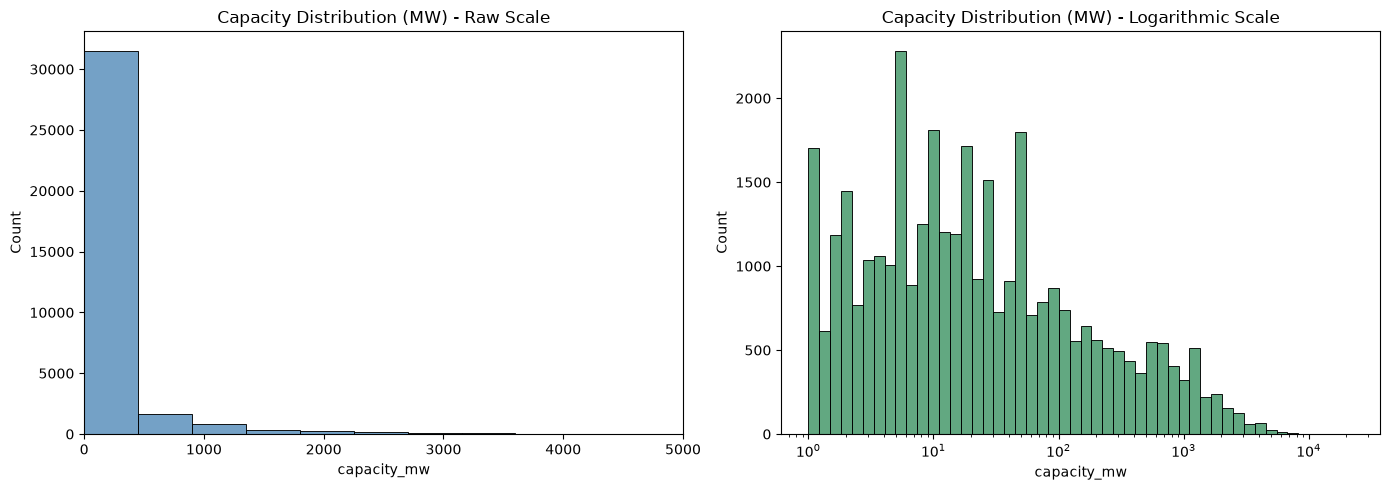

In [16]:
print(df['capacity_mw'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['capacity_mw'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Capacity Distribution (MW) - Raw Scale')
axes[0].set_xlim(0, 5000) # Zooming in on the majority of plants

sns.histplot(df['capacity_mw'], bins=50, ax=axes[1], color='seagreen', log_scale=True)
axes[1].set_title('Capacity Distribution (MW) - Logarithmic Scale')

plt.tight_layout()
plt.show()

In [17]:
fuel_analysis = df.groupby('primary_fuel').agg(
    Total_Plants=('capacity_mw', 'count'),
    Total_Capacity_MW=('capacity_mw', 'sum'),
    Mean_Capacity_MW=('capacity_mw', 'mean')
).sort_values(by='Total_Capacity_MW', ascending=False)

print(fuel_analysis)

                Total_Plants  Total_Capacity_MW  Mean_Capacity_MW
primary_fuel                                                     
Coal                    2330       1.965541e+06        843.579828
Gas                     3998       1.493051e+06        373.449375
Hydro                   7156       1.053160e+06        147.171551
Nuclear                  195       4.079118e+05       2091.855179
Wind                    5344       2.630537e+05         49.224126
Oil                     2320       2.618787e+05        112.878754
Solar                  10665       1.883123e+05         17.657039
Biomass                 1430       3.428130e+04         23.972938
Waste                   1068       1.474871e+04         13.809657
Geothermal               189       1.268775e+04         67.130952
Cogeneration              41       4.048000e+03         98.731707
Other                     43       3.612860e+03         84.020000
Petcoke                   12       2.424577e+03        202.048125
Storage   

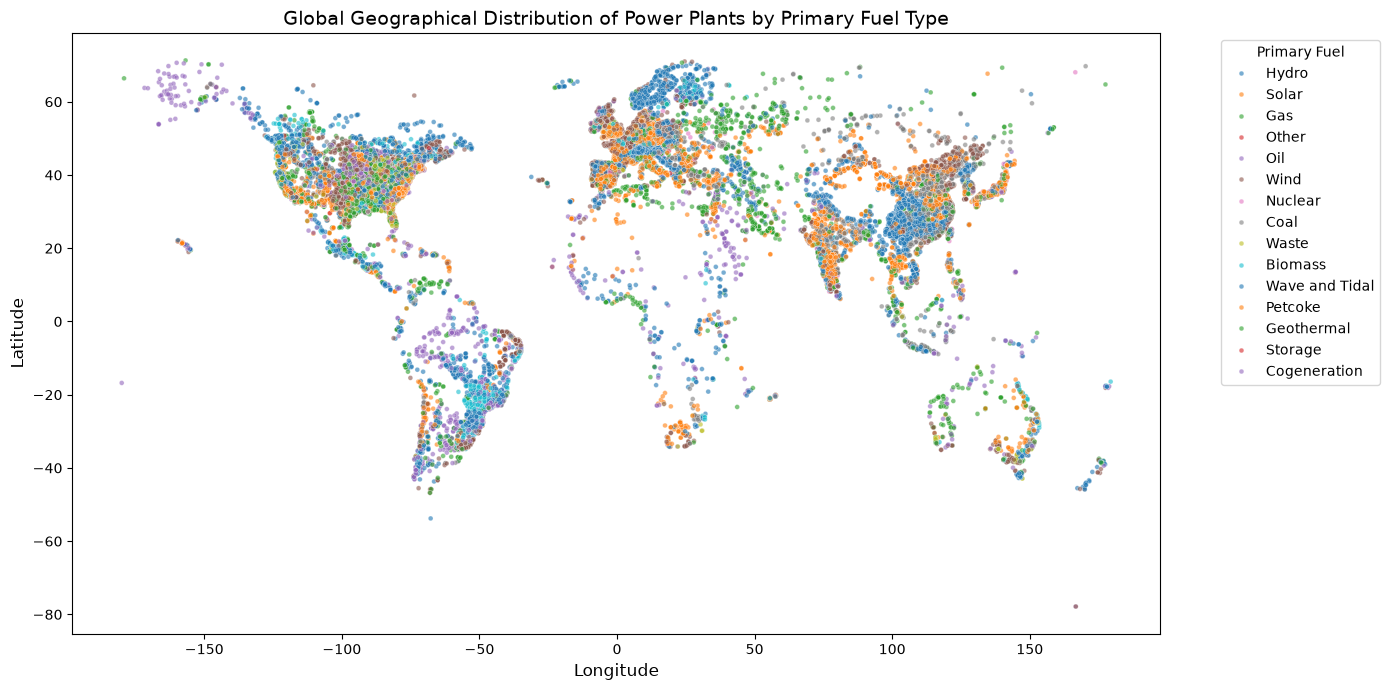

In [18]:
plt.figure(figsize=(14, 7))
sns.scatterplot(
    x='longitude', 
    y='latitude', 
    data=df, 
    hue='primary_fuel', 
    palette='tab10', 
    s=12, 
    alpha=0.6
)
plt.title('Global Geographical Distribution of Power Plants by Primary Fuel Type', fontsize=14)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Primary Fuel')
plt.tight_layout()
plt.show()

--- Top 10 Countries by Installed Capacity ---
                          Total_Plants  Total_Capacity_MW  Mean_Capacity_MW
country_long                                                               
China                             4235       1.415067e+06        334.136335
United States of America          9833       1.204638e+06        122.509717
India                             1589       3.160885e+05        198.922936
Russia                             545       2.282200e+05        418.752385
Japan                              522       2.153659e+05        412.578257
Brazil                            2360       1.475893e+05         62.537827
Canada                            1159       1.435787e+05        123.881536
Germany                           1309       1.120404e+05         85.592341
France                            2155       1.106159e+05         51.329897
South Korea                        132       9.947268e+04        753.580909


C:\Users\asier\AppData\Local\Temp\ipykernel_23144\1818717108.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.index, y=top_countries['Total_Capacity_MW'], palette='viridis')


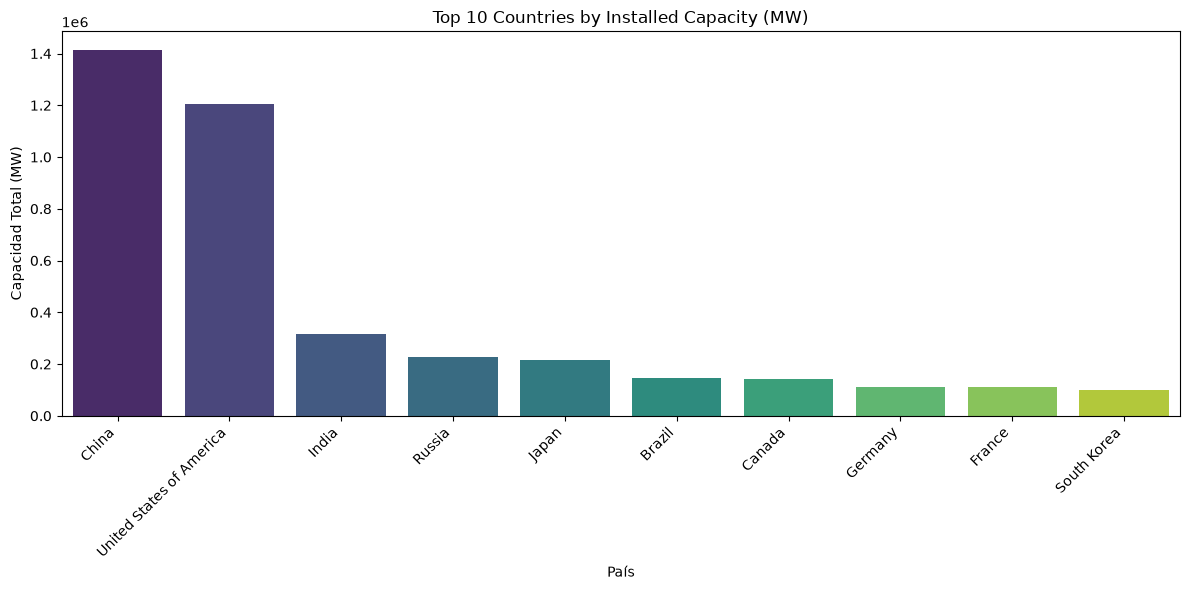

In [19]:
top_countries = df.groupby('country_long').agg(
    Total_Plants=('capacity_mw', 'count'),
    Total_Capacity_MW=('capacity_mw', 'sum'),
    Mean_Capacity_MW=('capacity_mw', 'mean')
).sort_values(by='Total_Capacity_MW', ascending=False).head(10)

print("--- Top 10 Countries by Installed Capacity ---")
print(top_countries)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.index, y=top_countries['Total_Capacity_MW'], palette='viridis')
plt.title('Top 10 Countries by Installed Capacity (MW)')
plt.xlabel('País')
plt.ylabel('Capacidad Total (MW)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

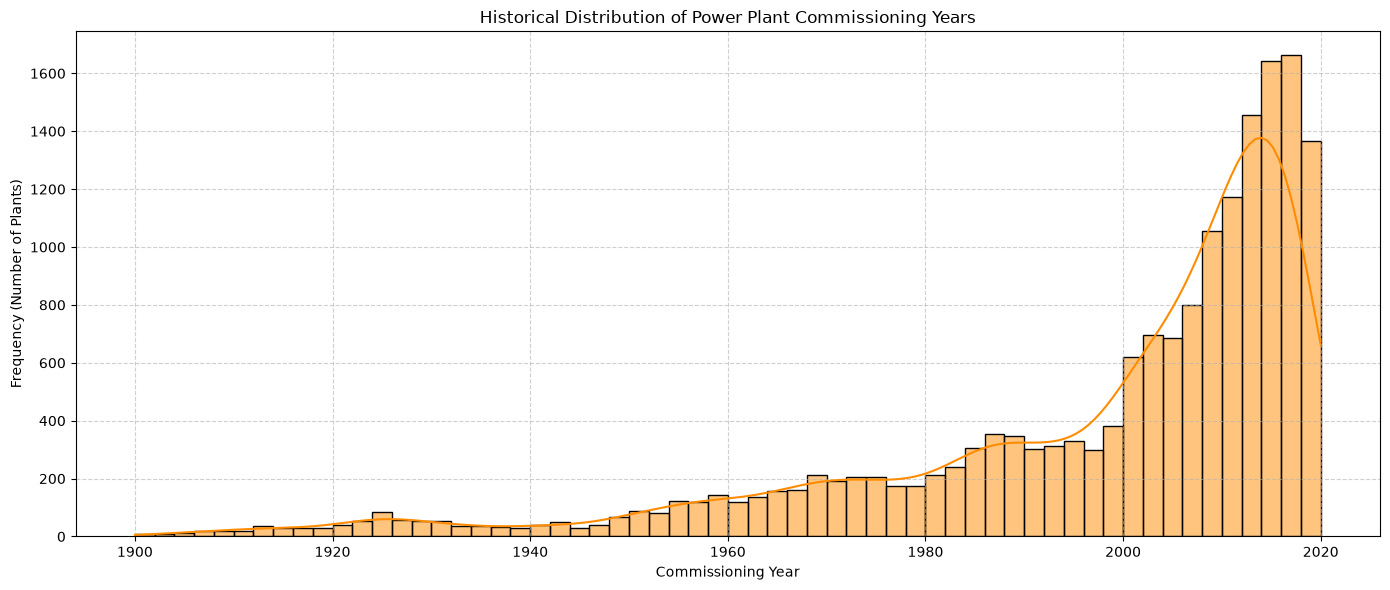

In [20]:
df_temporal = df.dropna(subset=['commissioning_year']).copy()
df_temporal = df_temporal[(df_temporal['commissioning_year'] >= 1900) & (df_temporal['commissioning_year'] <= 2026)]

plt.figure(figsize=(14, 6))
sns.histplot(df_temporal['commissioning_year'], bins=60, color='darkorange', kde=True)
plt.title('Historical Distribution of Power Plant Commissioning Years')
plt.xlabel('Commissioning Year')
plt.ylabel('Frequency (Number of Plants)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

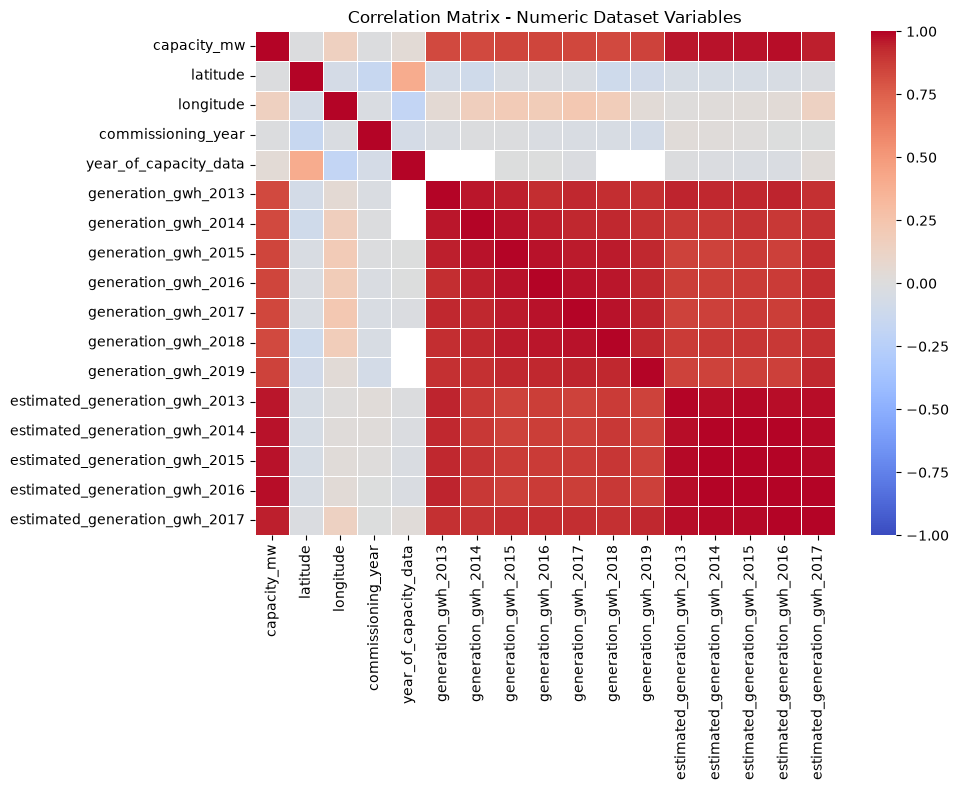


--- Correlation with the Target Variable (capacity_mw) ---
capacity_mw                      1.000000
estimated_generation_gwh_2016    0.977699
estimated_generation_gwh_2014    0.975443
estimated_generation_gwh_2015    0.973716
estimated_generation_gwh_2013    0.965684
estimated_generation_gwh_2017    0.948944
generation_gwh_2019              0.854440
generation_gwh_2016              0.844018
generation_gwh_2015              0.843868
generation_gwh_2017              0.843724
generation_gwh_2018              0.832101
generation_gwh_2014              0.830394
generation_gwh_2013              0.829836
longitude                        0.151525
year_of_capacity_data            0.042427
latitude                        -0.013218
commissioning_year              -0.013907
Name: capacity_mw, dtype: float64


In [21]:
numeric_df = df.select_dtypes(include=['float64', 'int64'])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix - Numeric Dataset Variables')
plt.tight_layout()
plt.show()

if 'capacity_mw' in corr_matrix.columns:
    print("\n--- Correlation with the Target Variable (capacity_mw) ---")
    print(corr_matrix['capacity_mw'].sort_values(ascending=False))

The dataset exhibits severe missingness in auxiliary variables (e.g., `other_fuel3` missing in 99.74% of records) and historical generation entries (>70% missing data between 2013 and 2019). Predictive models will require robust data cleaning, targeted imputation techniques, or the exclusion of sparsely populated features to prevent overfitting or distortion.


Plant capacity (`capacity_mw`) displays heavy positive skewness, with a median of 16.75 MW and a 75th percentile of 75.34 MW, contrasted against a mean of 163.36 MW and extreme outliers reaching up to 22,500 MW. Feature scaling, log-transformations, or prioritizing tree-based algorithms over linear models will be essential to handle these massive discrepancies effectively.


The distribution of technologies reveals contrasting patterns: while solar (10,665 plants) and hydro (7,156 plants) dominate in volume, coal leads in cumulative capacity (~1.96 million MW across 2,330 plants), and nuclear exhibits the highest average capacity per plant (2,091.86 MW). Future modeling should consider category-specific sub-models or robust categorical embeddings to capture the unique operational profiles of each energy source.

# Preprocessing

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, FunctionTransformer

In [23]:

target_col = "capacity_mw"

cols_to_drop = [
    "gppd_idnr", "name", "source", "url",
    "wepp_id", "geolocation_source", "owner"
]

df_model = df.drop(columns=cols_to_drop, errors="ignore").copy()
df_model = df_model.dropna(subset=[target_col]).copy()

for col in df_model.select_dtypes(include="object").columns:
    df_model[col] = df_model[col].replace(r"^\s*$", np.nan, regex=True)

for col in df_model.columns:
    if col != target_col and pd.api.types.is_numeric_dtype(df_model[col]):
        df_model[col] = pd.to_numeric(df_model[col], errors="coerce")

X = df_model.drop(columns=[target_col])
y = pd.to_numeric(df_model[target_col], errors="coerce")

valid_idx = y.notna() & np.isfinite(y)
X = X.loc[valid_idx]
y = y.loc[valid_idx]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cols_to_remove = X_train.columns[
    X_train.isna().all() |
    (X_train.nunique(dropna=True) <= 1)
].tolist()

X_train = X_train.drop(columns=cols_to_remove)
X_test = X_test.drop(columns=cols_to_remove)

numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

preprocessor.set_output(transform="pandas")

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("X_train:", X_train_prep.shape)
print("X_test:", X_test_prep.shape)
print("Train NaN:", X_train_prep.isna().sum().sum())
print("Test NaN:", X_test_prep.isna().sum().sum())


C:\Users\asier\AppData\Local\Temp\ipykernel_23144\78723446.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_model.select_dtypes(include="object").columns:


X_train: (27948, 238)
X_test: (6988, 238)
Train NaN: 0
Test NaN: 0


--- Top 15 Features by Mutual Information ---


,Feature,Mutual_Information_Score
0,estimated_generation_gwh_2017,2.391254
1,estimated_generation_gwh_2016,1.120059
2,estimated_generation_gwh_2015,1.075977
3,estimated_generation_gwh_2014,1.070202
4,estimated_generation_gwh_2013,1.003454
5,generation_gwh_2019,0.365020
6,longitude,0.344055
7,generation_gwh_2018,0.329328
8,generation_gwh_2017,0.314677
9,generation_gwh_2016,0.296488


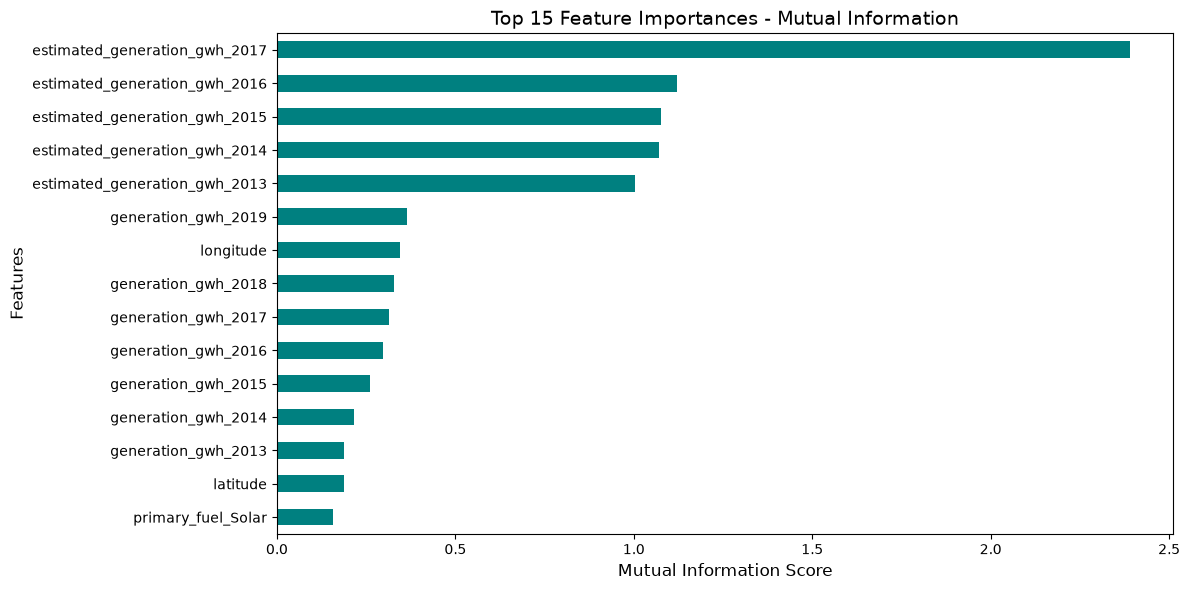

In [25]:
from sklearn.feature_selection import mutual_info_regression


mi_scores = mutual_info_regression(X_train_prep, y_train, random_state=42)

mi_scores = pd.Series(mi_scores, index=X_train_prep.columns).sort_values(ascending=False)

print("--- Top 15 Features by Mutual Information ---")
top_mi_df = mi_scores.head(15).reset_index()
top_mi_df.columns = ["Feature", "Mutual_Information_Score"]
display(top_mi_df)

plt.figure(figsize=(12, 6))
mi_scores.head(15).plot(kind="barh", color="teal")
plt.gca().invert_yaxis()  
plt.title("Top 15 Feature Importances - Mutual Information", fontsize=14)
plt.xlabel("Mutual Information Score", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()
plt.show()

# Model Building

## Baseline Model 

In [28]:
import time
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Dummy": DummyRegressor(strategy="median"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    )
}

print("Starting model comparison...")
total_start = time.time()

comparison = []
fitted_models = {}

for i, (name, estimator) in enumerate(models.items(), 1):

    model_start = time.time()

    print(f"\n[{i}/{len(models)}] Starting {name}...")

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    print(f"[{name}] Running cross-validation...")

    cv = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    print(f"[{name}] Cross-validation completed.")
    print(f"[{name}] Fitting model...")

    pipe.fit(X_train, y_train)

    print(f"[{name}] Model fitted. Predicting test data...")

    predictions = pipe.predict(X_test)

    comparison.append({
        "Model": name,
        "CV MAE": -cv["test_mae"].mean(),
        "CV RMSE": -cv["test_rmse"].mean(),
        "CV R2": cv["test_r2"].mean(),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R2": r2_score(y_test, predictions)
    })

    fitted_models[name] = pipe

    print(f"[{name}] Completed in {time.time() - model_start:.2f} seconds.")

comparison_df = pd.DataFrame(comparison).sort_values(
    "CV RMSE"
).reset_index(drop=True)

print("\nAll models completed!")
print(f"Total execution time: {time.time() - total_start:.2f} seconds")

display(comparison_df.round(4))


Starting model comparison...

[1/4] Starting Dummy...
[Dummy] Running cross-validation...
[Dummy] Cross-validation completed.
[Dummy] Fitting model...
[Dummy] Model fitted. Predicting test data...
[Dummy] Completed in 3.32 seconds.

[2/4] Starting Linear Regression...
[Linear Regression] Running cross-validation...
[Linear Regression] Cross-validation completed.
[Linear Regression] Fitting model...
[Linear Regression] Model fitted. Predicting test data...
[Linear Regression] Completed in 9.86 seconds.

[3/4] Starting Random Forest...
[Random Forest] Running cross-validation...
[Random Forest] Cross-validation completed.
[Random Forest] Fitting model...
[Random Forest] Model fitted. Predicting test data...
[Random Forest] Completed in 361.03 seconds.

[4/4] Starting XGBoost...
[XGBoost] Running cross-validation...
[XGBoost] Cross-validation completed.
[XGBoost] Fitting model...
[XGBoost] Model fitted. Predicting test data...
[XGBoost] Completed in 15.07 seconds.

All models completed!
T

,Model,CV MAE,CV RMSE,CV R2,Test MAE,Test RMSE,Test R2
0,Random Forest,17.8338,94.2350,0.9605,19.9843,195.8144,0.8662
1,XGBoost,32.0999,124.5330,0.9316,34.3653,231.9800,0.8122
2,Linear Regression,44.7834,128.3476,0.9273,45.9256,147.1427,0.9244
3,Dummy,157.1442,499.3629,-0.0939,159.3996,555.5626,-0.0770


## Model Analysis

### Hyperparameter tuning 

In [29]:
from sklearn.model_selection import RandomizedSearchCV

print("[1/5] Creating Random Forest pipeline...")

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

print("[2/5] Defining hyperparameter search space...")

param_grid = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.6, 0.8, 1.0]
}

print("[3/5] Configuring RandomizedSearchCV...")

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("[4/5] Starting model training and hyperparameter search...")
print("Total fits:", 10 * 3)
print("This may take some time...")

rf_search.fit(X_train, y_train)

print("[5/5] Training completed!")

print("Extracting best model...")
best_model = rf_search.best_estimator_

print("\nBest parameters:")
print(rf_search.best_params_)

print("\nBest CV RMSE:", round(-rf_search.best_score_, 4))

print("\nAll processes completed successfully!")


[1/5] Creating Random Forest pipeline...
[2/5] Defining hyperparameter search space...
[3/5] Configuring RandomizedSearchCV...
[4/5] Starting model training and hyperparameter search...
Total fits: 30
This may take some time...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[5/5] Training completed!
Extracting best model...

Best parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': 20}

Best CV RMSE: 105.6566

All processes completed successfully!


In [31]:
print("[1/5] Creating XGBoost pipeline...")

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        random_state=42,
        objective="reg:squarederror",
        n_jobs=1
    ))
])

print("[2/5] Defining hyperparameter search space for XGBoost...")

param_grid_xgb = {
    "model__n_estimators": [150, 250, 400],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [3, 5, 7],
    "model__subsample": [0.7, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.9, 1.0]
}

print("[3/5] Configuring RandomizedSearchCV...")

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid_xgb,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("[4/5] Starting model training and hyperparameter search...")
print("Total fits:", 10 * 3)
print("This may take some time...")

xgb_search.fit(X_train, y_train)

print("[5/5] Training completed!")

print("Extracting best XGBoost model...")
best_xgb_model = xgb_search.best_estimator_

print("\nBest parameters for XGBoost:")
print(xgb_search.best_params_)

print("\nBest CV RMSE (XGBoost):", round(-xgb_search.best_score_, 4))

print("\nAll processes completed successfully!")

[1/5] Creating XGBoost pipeline...
[2/5] Defining hyperparameter search space for XGBoost...
[3/5] Configuring RandomizedSearchCV...
[4/5] Starting model training and hyperparameter search...
Total fits: 30
This may take some time...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[5/5] Training completed!
Extracting best XGBoost model...

Best parameters for XGBoost:
{'model__subsample': 1.0, 'model__n_estimators': 400, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.9}

Best CV RMSE (XGBoost): 117.6832

All processes completed successfully!


In [ ]:
models_to_test = {
    "Random Forest (Optimized)": best_model,
    "XGBoost (Optimized)": best_xgb_model
}

test_results = []

print("Evaluating models on test data...")

for name, model in models_to_test.items():
    predictions = model.predict(X_test)
    
    test_results.append({
        "Model": name,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test R2": r2_score(y_test, predictions)
    })

test_comparison_df = pd.DataFrame(test_results).sort_values("Test RMSE").reset_index(drop=True)

print("\nFinal Test Comparison:")
display(test_comparison_df.round(4))

Evaluating models on test data...

Final Test Comparison:


,Model,Test RMSE,Test MAE,Test R2
0,Random Forest (Optimized),194.7519,21.3742,0.8677
1,XGBoost (Optimized),229.7913,24.8021,0.8157


Let's write a cell that hardcodes that optimized random forest so we can later skip the tuning 

In [33]:
import time
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

start_time = time.time()

final_rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features=0.8,
        random_state=42,
        n_jobs=-1  
    ))
])

print("Training final Random Forest model...")
final_rf_pipeline.fit(X_train, y_train)
print(f"Training completed in {time.time() - start_time:.2f} segundos.")

y_pred = final_rf_pipeline.predict(X_test)

metrics = pd.DataFrame([{
    "Model": "Random Forest (Hardcoded Best)",
    "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "Test MAE": mean_absolute_error(y_test, y_pred),
    "Test R2": r2_score(y_test, y_pred)
}])

display(metrics.round(4))

Training final Random Forest model...
Training completed in 84.65 segundos.


,Model,Test RMSE,Test MAE,Test R2
0,Random Forest (Hardcoded Best),194.7519,21.3742,0.8677


### Feature Importance

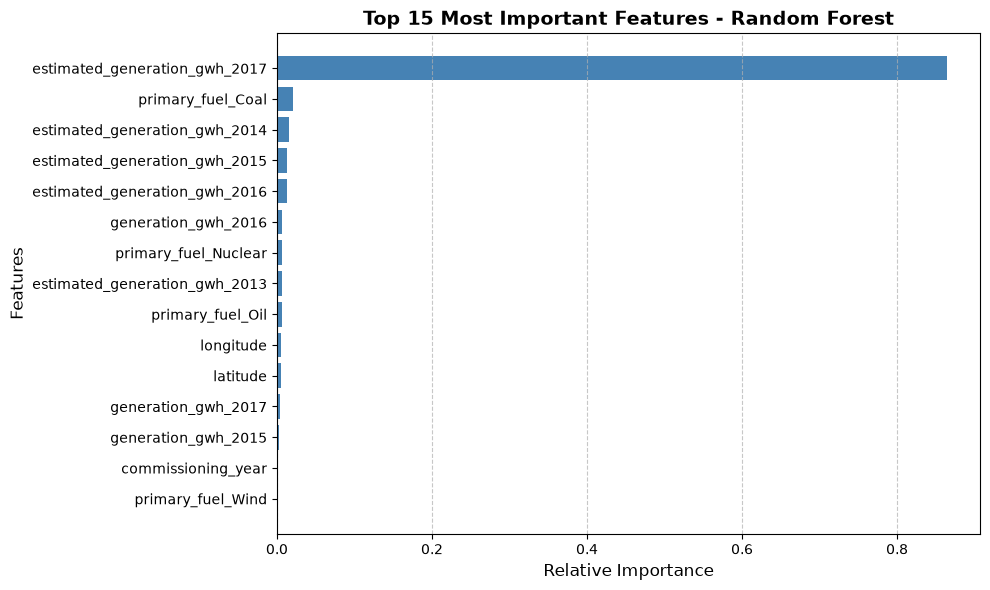

In [34]:
try:
    feature_names = final_rf_pipeline.named_steps['preprocessor'].get_feature_names_out()
except AttributeError:
    feature_names = [f"feat_{i}" for i in range(len(final_rf_pipeline.named_steps['model'].feature_importances_))]

importances = final_rf_pipeline.named_steps['model'].feature_importances_

feat_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(feat_importance_df['Feature'], feat_importance_df['Importance'], color='steelblue')
plt.xlabel('Relative Importance', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Top 15 Most Important Features - Random Forest', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Residual Analysis

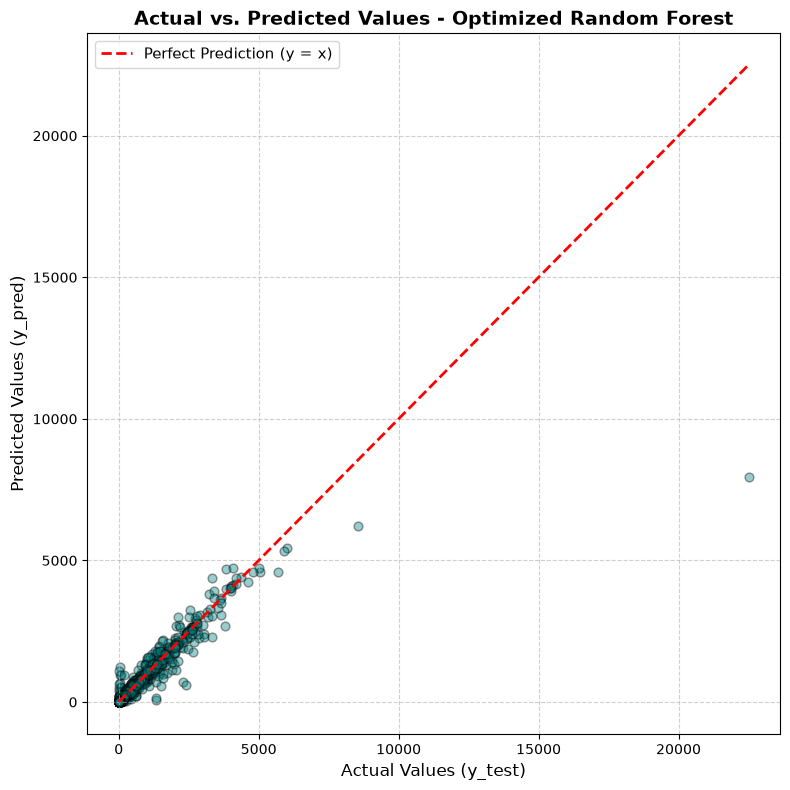

In [35]:
plt.figure(figsize=(8, 8))

plt.scatter(y_test, y_pred, alpha=0.4, color='teal', edgecolor='k', s=40)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction (y = x)')

plt.xlabel('Actual Values (y_test)', fontsize=12)
plt.ylabel('Predicted Values (y_pred)', fontsize=12)
plt.title('Actual vs. Predicted Values - Optimized Random Forest', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

We see that the RMSE wasn't great because of that outlier megaplant 